# Three-qubit repetition code: a single coherent CNOT fault

The logical basis is $|0_L\rangle=|000\rangle$, $|1_L\rangle=|111\rangle$.
The two checks $Z_0Z_1$ and $Z_1Z_2$ yield a conceptual syndrome $s_0s_1$.
Every CNOT has a target $R_x(\theta_g)$ parameter, but only `enc_0_1` is
nonzero in this experiment. We measure *finite-shot* data, not exact state
probabilities, and compare it against a separate analytical prediction.

In [2]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from qec_calibration import (
    SPSAConfig, build_syndrome_template, calibrate_spsa, cnot_locations,
    counts_to_probabilities, logical_success_probability, parameter_norm,
    run_recovery, run_syndrome, single_fault_response_rank,
    syndrome_for_errors, theoretical_single_fault_probabilities,
)

FAST_MODE = False  # True for a quick exploratory run; False for full experiment
MAXITER = 15 if FAST_MODE else 100
TRAIN_SHOTS = 256 if FAST_MODE else 1024
VALIDATION_SHOTS = 1024 if FAST_MODE else 4096
REPEATS = 1 if FAST_MODE else 3
SEED = 42

N = 3
SWEEP_SHOTS = 1024 if FAST_MODE else 4096
model = build_syndrome_template(N)
print("CNOT locations:", model.gate_ids)
print(model.circuit.draw(output="text"))


CNOT locations: ('enc_0_1', 'enc_0_2', 'syn_0_left', 'syn_0_right', 'syn_1_left', 'syn_1_right')
                                                       ░  ░      »
    data_0: ──■────────────────────■───────────────────░──░───■──»
            ┌─┴─┐┌──────────────┐  │                   ░  ░   │  »
    data_1: ┤ X ├┤ Rx(theta[0]) ├──┼───────────────────░──░───┼──»
            └───┘└──────────────┘┌─┴─┐┌──────────────┐ ░  ░   │  »
    data_2: ─────────────────────┤ X ├┤ Rx(theta[1]) ├─░──░───┼──»
                                 └───┘└──────────────┘ ░  ░ ┌─┴─┐»
 ancilla_0: ───────────────────────────────────────────░──░─┤ X ├»
                                                       ░  ░ └───┘»
 ancilla_1: ───────────────────────────────────────────░──░──────»
                                                       ░  ░      »
syndrome: 2/═════════════════════════════════════════════════════»
                                                                 »
«                               

## 1. Ideal syndrome table

The parity bits compare neighboring data qubits. Verify each known physical
bit flip with shots from the ideal circuit.

In [3]:
ideal_rows = []
for errors in ((), (0,), (1,), (2,)):
    probe = build_syndrome_template(N, physical_errors=errors)
    counts = run_syndrome(probe, shots=128, seed=SEED)
    ideal_rows.append({"physical_X": str(errors), "expected": syndrome_for_errors(N, errors), "measured_counts": counts})
ideal_table = pd.DataFrame(ideal_rows)
display(ideal_table)
assert all(list(row["measured_counts"]) == [row["expected"]] for row in ideal_rows)


,physical_X,expected,measured_counts
0,(),00,{'00': 128}
1,"(0,)",10,{'10': 128}
2,"(1,)",11,{'11': 128}
3,"(2,)",01,{'01': 128}


## 2. Analytical single-fault prediction

The first encoding CNOT leaves $R_x^{(1)}(\epsilon)$ on data qubit 1.
Because later encoding gates commute with $X_1$,

$$|\Psi(\epsilon)\rangle=\cos(\epsilon/2)|\psi_L\rangle
-i\sin(\epsilon/2)X_1|\psi_L\rangle.$$

These branches have syndromes `00` and `11`, hence
$P(00)=\cos^2(\epsilon/2)$, $P(11)=\sin^2(\epsilon/2)$,
and $P(10)=P(01)=0$. The no-error calibration loss is $1-P(00)$.

In [4]:
epsilon_values = np.linspace(-1.0, 1.0, 11 if FAST_MODE else 21)
rows = []
for index, epsilon in enumerate(epsilon_values):
    counts = run_syndrome(model, {"enc_0_1": epsilon}, shots=SWEEP_SHOTS, seed=SEED + index)
    sampled = counts_to_probabilities(counts, N)
    theory = theoretical_single_fault_probabilities(N, epsilon)
    for syndrome in ("00", "10", "11", "01"):
        rows.append({"epsilon": epsilon, "syndrome": syndrome, "sampled": sampled[syndrome], "theory": theory[syndrome]})
sweep = pd.DataFrame(rows)
display(sweep.head(8))


,epsilon,syndrome,sampled,theory
0,-1.0,00,0.775146,0.770151
1,-1.0,10,0.000000,0.000000
2,-1.0,11,0.224854,0.229849
3,-1.0,01,0.000000,0.000000
4,-0.9,00,0.811768,0.810805
5,-0.9,10,0.000000,0.000000
6,-0.9,11,0.188232,0.189195
7,-0.9,01,0.000000,0.000000


## 3. Finite-shot syndrome probabilities and calibration signal

Dots are sampled measurements; curves are theory. The second plot isolates the
same quantity that the later SPSA notebooks optimize.

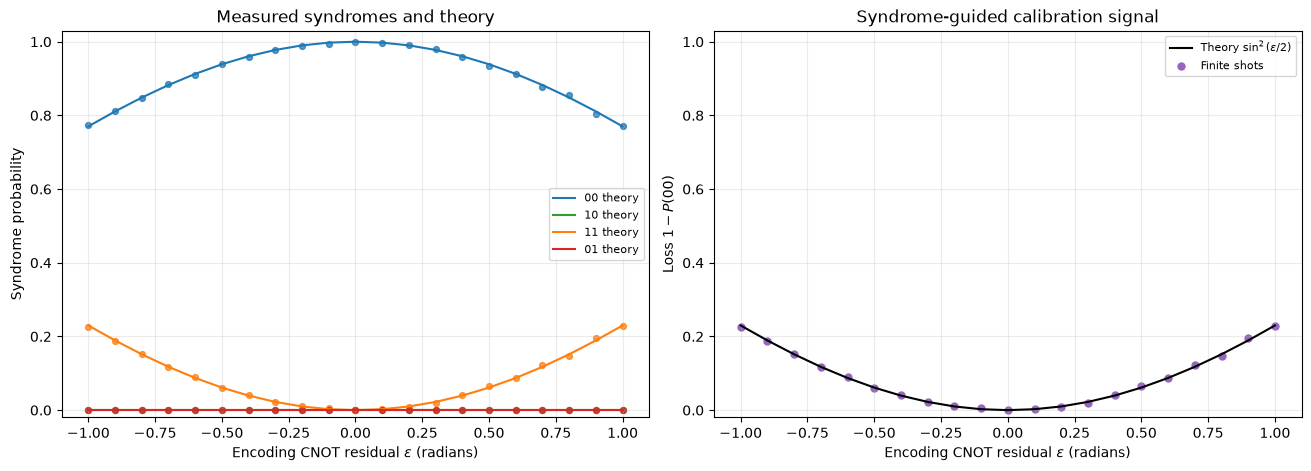

Maximum sampled/theory deviation: 0.0068; shots per point: 4096


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
colors = {"00": "tab:blue", "10": "tab:green", "11": "tab:orange", "01": "tab:red"}
for syndrome, color in colors.items():
    part = sweep[sweep.syndrome == syndrome]
    axes[0].plot(part.epsilon, part.theory, color=color, label=f"{syndrome} theory")
    axes[0].scatter(part.epsilon, part.sampled, color=color, s=18, marker="o", alpha=0.75)
base = sweep[sweep.syndrome == "00"]
axes[1].plot(base.epsilon, 1 - base.theory, color="black", label=r"Theory $\sin^2(\epsilon/2)$")
axes[1].scatter(base.epsilon, 1 - base.sampled, color="tab:purple", s=25, label="Finite shots")
for ax in axes:
    ax.set(xlabel=r"Encoding CNOT residual $\epsilon$ (radians)", ylim=(-0.02, 1.03))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set(ylabel="Syndrome probability", title="Measured syndromes and theory")
axes[1].set(ylabel=r"Loss $1-P(00)$", title="Syndrome-guided calibration signal")
plt.savefig("syndrome_signal.pdf")
plt.show()

max_error = (sweep.sampled - sweep.theory).abs().max()
print(f"Maximum sampled/theory deviation: {max_error:.4f}; shots per point: {SWEEP_SHOTS}")
assert max_error < (0.08 if FAST_MODE else 0.04)


The finite-shot curve agrees with the predicted sinusoidal loss.
It measures the *magnitude* of a single residual near zero but is symmetric
under $\epsilon\mapsto-\epsilon$; calibration finds a minimum through active
parameter probes rather than estimating the sign from one static distribution.